In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Project directory
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Dataset path
DATA_PATH = BASE_DIR / "outputs" / "warning_data.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

df["timestamp"] = pd.to_datetime(df["timestamp"])

print("WARNING dataset loaded successfully!")

print("Dataset shape:", df.shape)

df.head()

WARNING dataset loaded successfully!
Dataset shape: (14477, 54)


,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status,target
0,2018-04-12 21:56:00,0.000000,53.55902,52.77777,43.402775,204.725098,53.74214,3.045428,17.42621,15.740740,...,50.34722,51.21528,49.18982,49.47917,431.7130,133.1019,419.2708,341.7245,RECOVERING,WARNING
1,2018-04-12 21:57:00,0.000000,53.55902,52.77777,43.402775,201.137131,52.49996,7.537616,13.53443,9.324364,...,49.76852,50.92593,48.03241,53.81944,451.3889,140.0463,433.1597,466.1458,RECOVERING,WARNING
2,2018-04-12 21:58:00,0.000000,52.77777,52.69097,43.402770,204.030655,57.19875,7.609953,16.60880,16.203700,...,48.03241,50.34722,47.45370,58.15972,466.4352,144.9653,442.7083,366.0301,RECOVERING,WARNING
3,2018-04-12 21:59:00,0.000000,52.60416,52.73437,43.446180,203.567688,50.96181,7.573785,16.70284,16.160300,...,47.45370,49.76852,46.58565,63.65741,474.8264,149.0162,449.6528,374.4213,RECOVERING,WARNING
4,2018-04-12 22:00:00,2.456539,52.51736,52.69097,43.446180,203.567688,49.78948,7.559317,16.56539,16.239870,...,46.29630,48.03241,45.13889,75.23148,477.7199,162.6157,448.7847,356.1921,RECOVERING,WARNING


In [3]:
print("========== DATASET INFORMATION ==========")

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

========== DATASET INFORMATION ==========

Dataset shape:
(14477, 54)

Column names:
['timestamp', 'sensor_00', 'sensor_01', 'sensor_02', 'sensor_03', 'sensor_04', 'sensor_05', 'sensor_06', 'sensor_07', 'sensor_08', 'sensor_09', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'sensor_22', 'sensor_23', 'sensor_24', 'sensor_25', 'sensor_26', 'sensor_27', 'sensor_28', 'sensor_29', 'sensor_30', 'sensor_31', 'sensor_32', 'sensor_33', 'sensor_34', 'sensor_35', 'sensor_36', 'sensor_37', 'sensor_38', 'sensor_39', 'sensor_40', 'sensor_41', 'sensor_42', 'sensor_43', 'sensor_44', 'sensor_45', 'sensor_46', 'sensor_47', 'sensor_48', 'sensor_49', 'sensor_50', 'sensor_51', 'machine_status', 'target']

Data types:
timestamp         datetime64[us]
sensor_00                float64
sensor_01                float64
sensor_02                float64
sensor_03                float64
sensor_04                float64

In [4]:
print("========== MISSING VALUES ==========")

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

print("\nTotal missing values:")
print(df.isnull().sum().sum())

========== MISSING VALUES ==========
Series([], dtype: int64)

Total missing values:
0


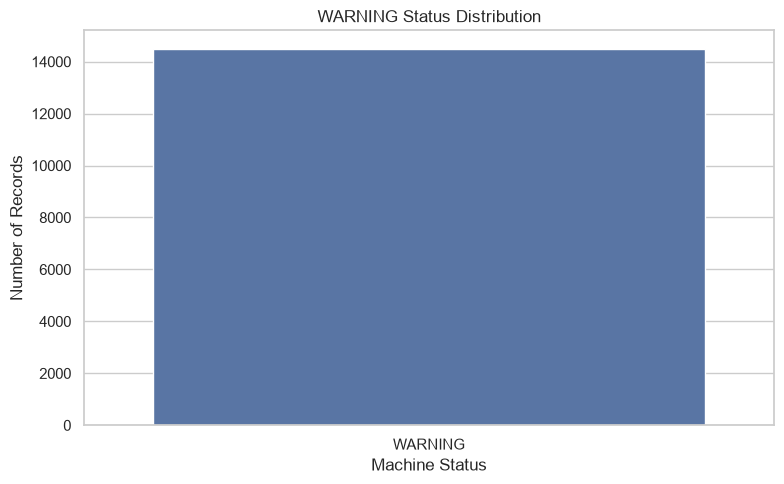

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="target"
)

plt.title("WARNING Status Distribution")

plt.xlabel("Machine Status")

plt.ylabel("Number of Records")

plt.tight_layout()

plt.show()

In [6]:
sensor_columns = [
    col for col in df.columns
    if col.startswith("sensor_")
]

print("Total sensor columns:", len(sensor_columns))

print("\n========== SENSOR STATISTICS ==========")

df[sensor_columns].describe().T

Total sensor columns: 51

========== SENSOR STATISTICS ==========


,count,mean,std,min,25%,50%,75%,max
sensor_00,14477.0,1.746111,1.099649,0.000000,0.109201,2.456539,2.456539,2.456539
sensor_01,14477.0,39.239854,4.382883,32.204860,35.373264,38.671880,41.059020,53.559020
sensor_02,14477.0,39.926751,5.131000,33.159720,36.067707,38.715275,42.187500,53.559020
sensor_03,14477.0,37.858898,3.505749,31.640620,34.895830,37.717014,40.538190,46.701390
sensor_04,14477.0,93.220460,118.361795,2.798032,3.336227,3.567708,203.029495,632.638916
sensor_05,14477.0,45.070925,49.423332,0.000000,0.000000,0.000000,99.999878,99.999880
sensor_06,14477.0,8.381604,5.563946,0.014468,0.028935,10.098380,13.642940,22.251160
sensor_07,14477.0,11.376593,6.736355,0.000000,9.852430,15.082470,16.167530,23.596640
sensor_08,14477.0,11.361140,6.400176,0.028935,10.098380,12.818290,15.494790,24.348960
sensor_09,14477.0,10.803058,6.588921,0.000000,8.796296,15.010130,15.082470,25.000000


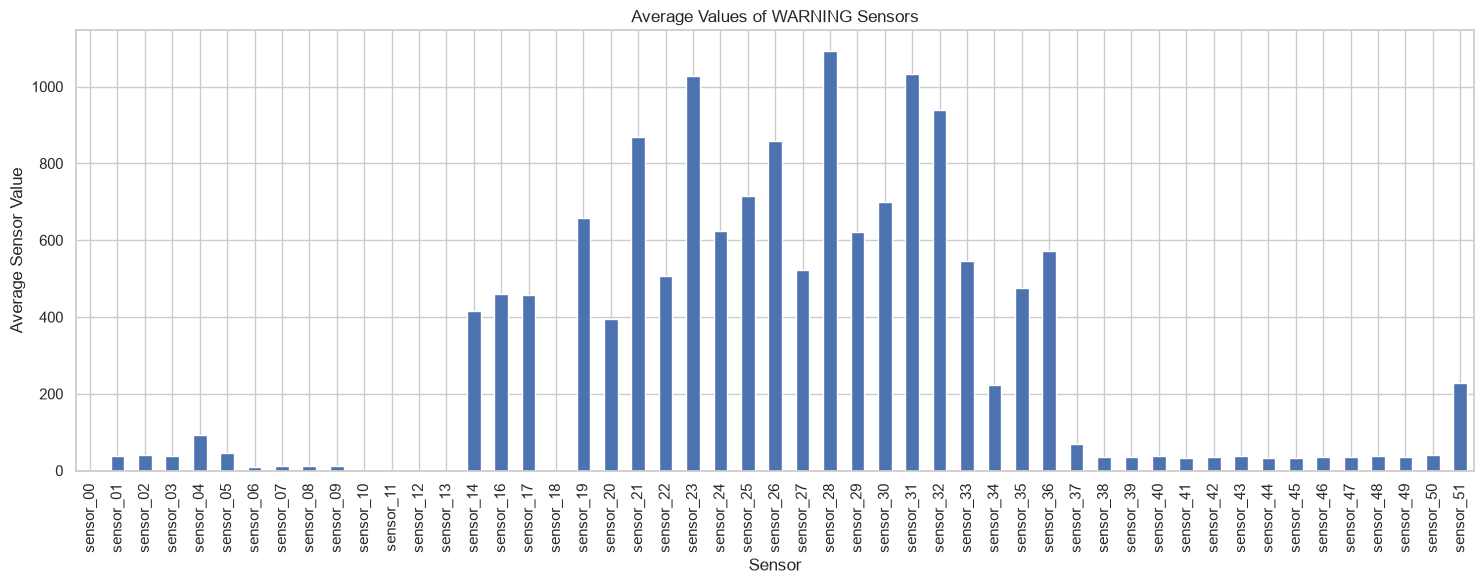

In [7]:
sensor_means = df[sensor_columns].mean()

plt.figure(figsize=(15, 6))

sensor_means.plot(kind="bar")

plt.title("Average Values of WARNING Sensors")

plt.xlabel("Sensor")

plt.ylabel("Average Sensor Value")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

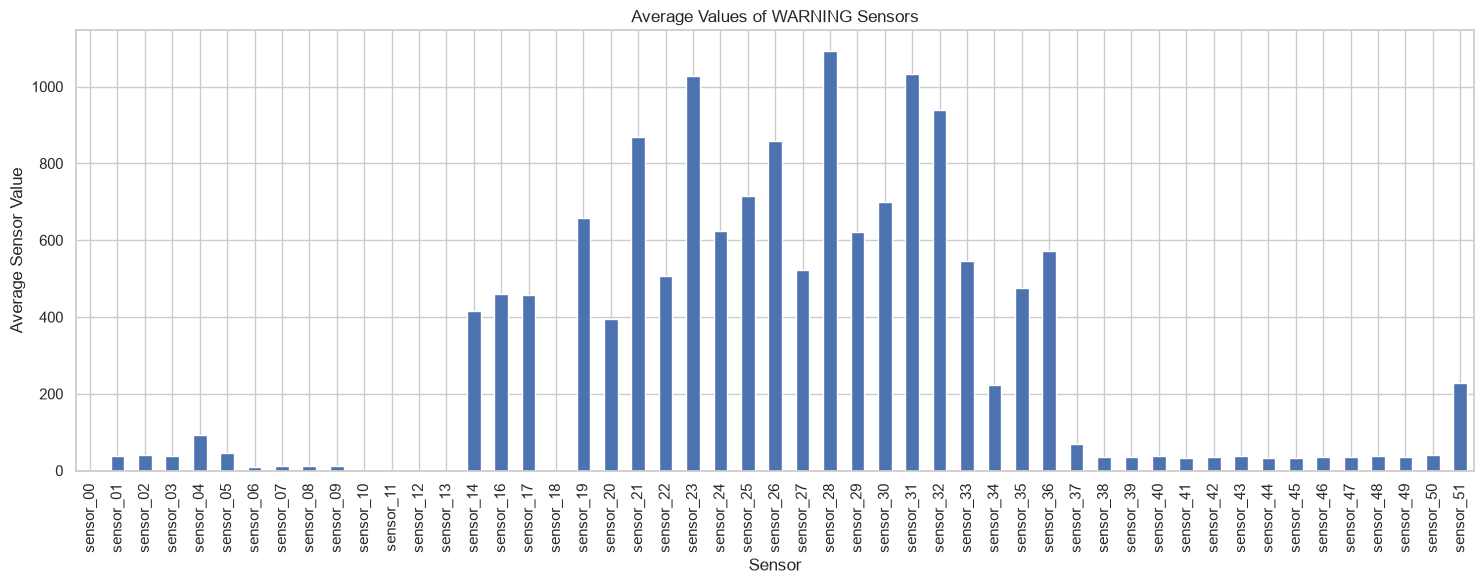

In [8]:
sensor_means = df[sensor_columns].mean()

plt.figure(figsize=(15, 6))

sensor_means.plot(kind="bar")

plt.title("Average Values of WARNING Sensors")

plt.xlabel("Sensor")

plt.ylabel("Average Sensor Value")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

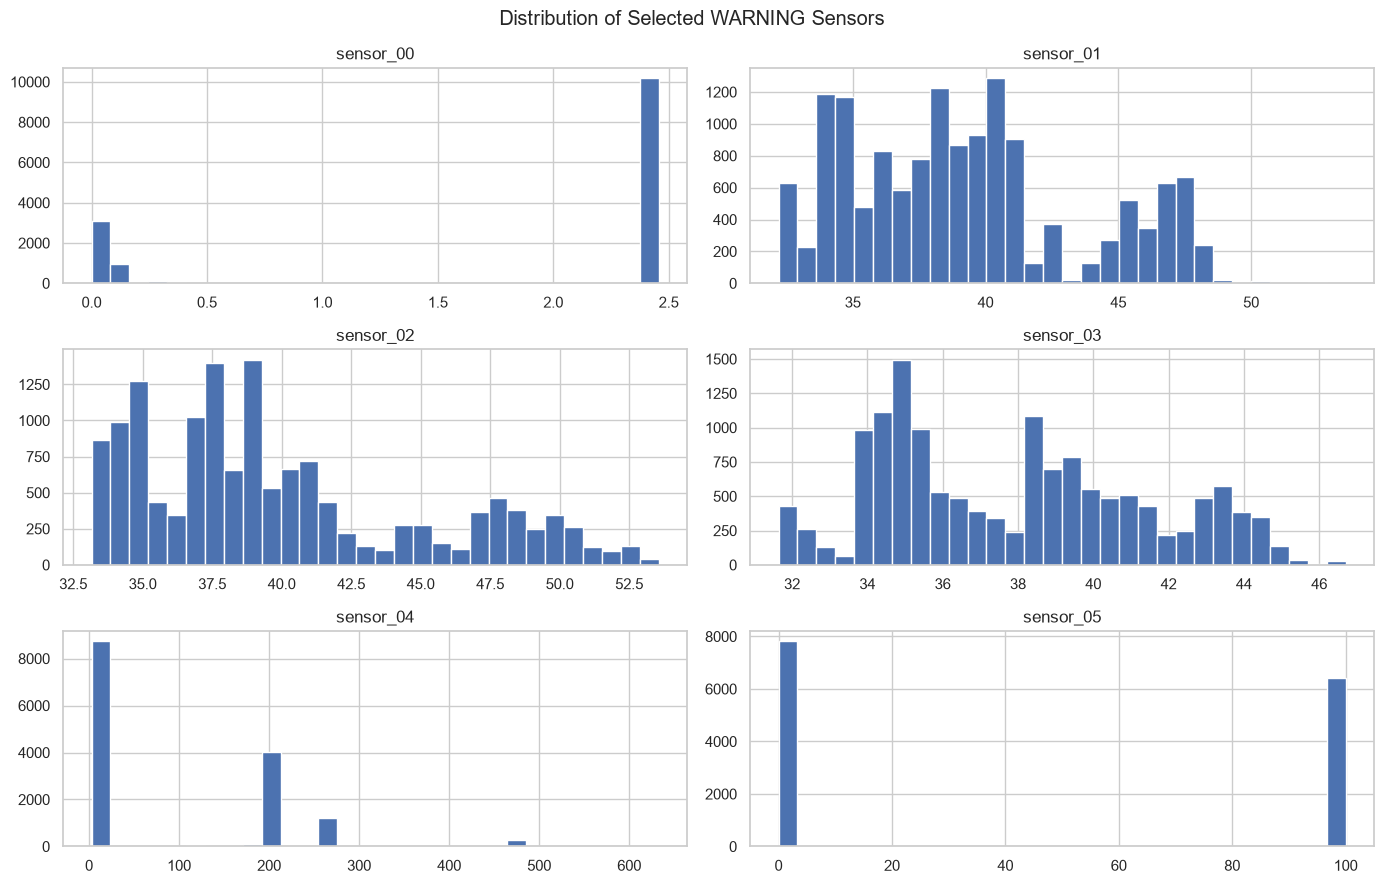

In [9]:
selected_sensors = sensor_columns[:6]

df[selected_sensors].hist(
    figsize=(14, 9),
    bins=30
)

plt.suptitle(
    "Distribution of Selected WARNING Sensors"
)

plt.tight_layout()

plt.show()

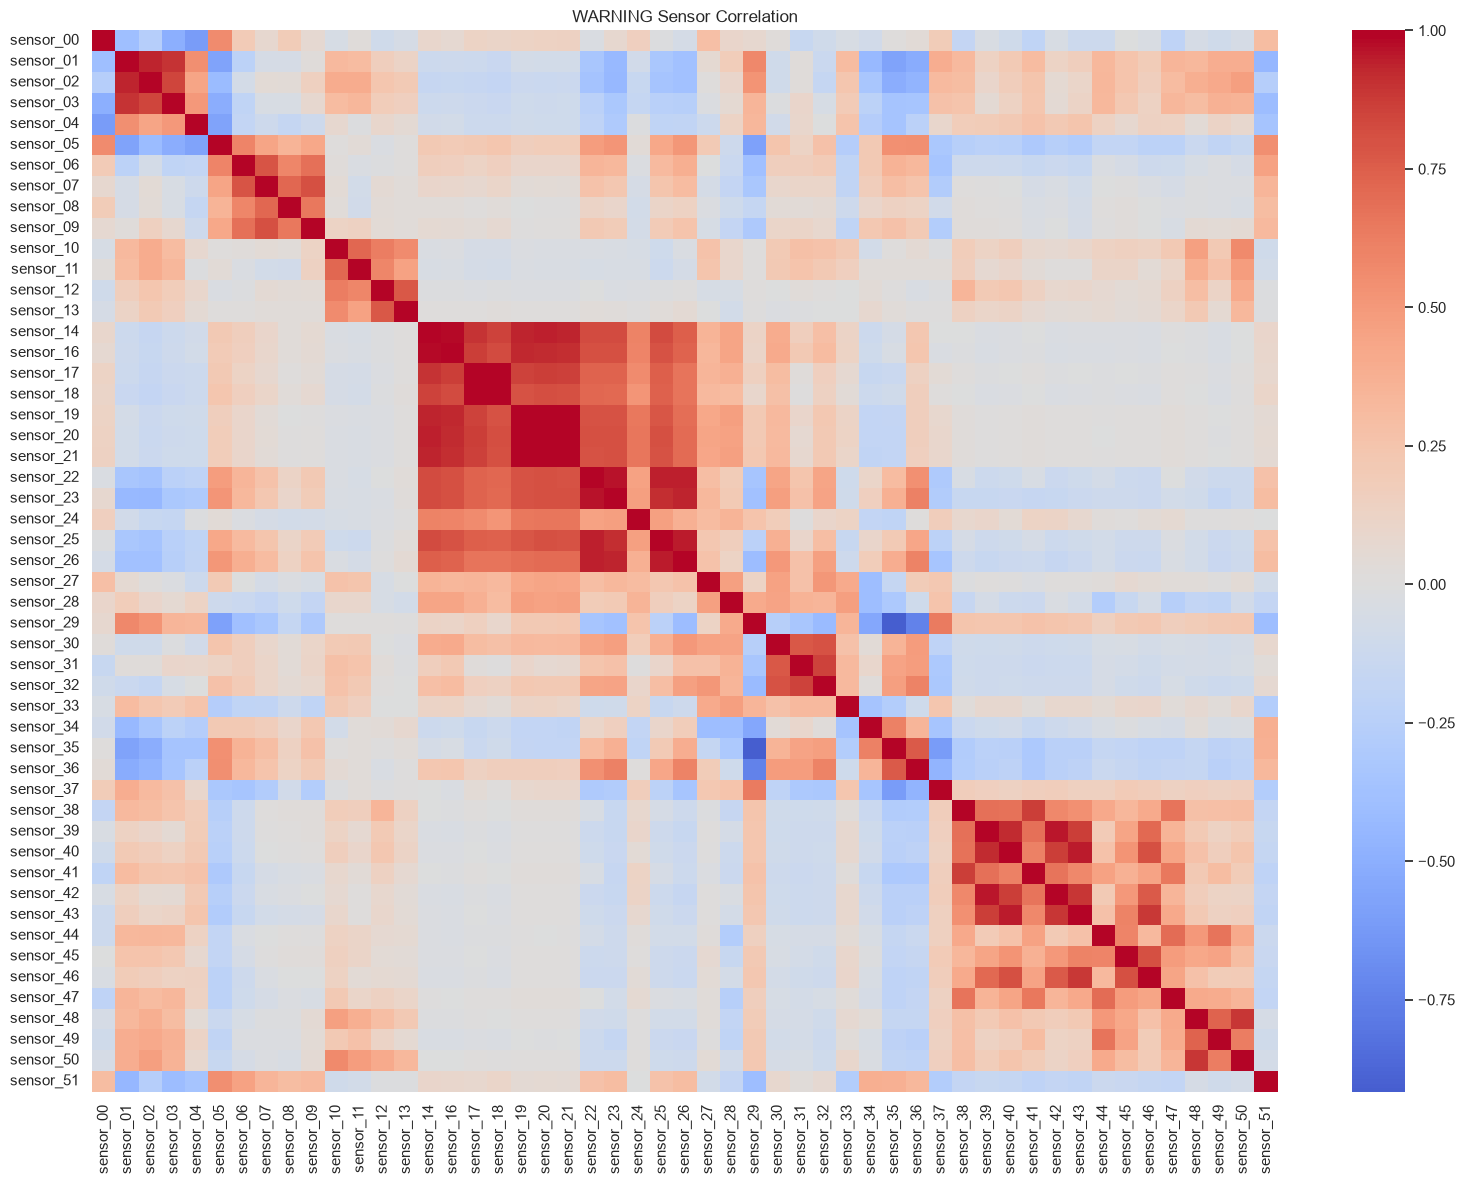

In [10]:
correlation = df[sensor_columns].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("WARNING Sensor Correlation")

plt.tight_layout()

plt.show()

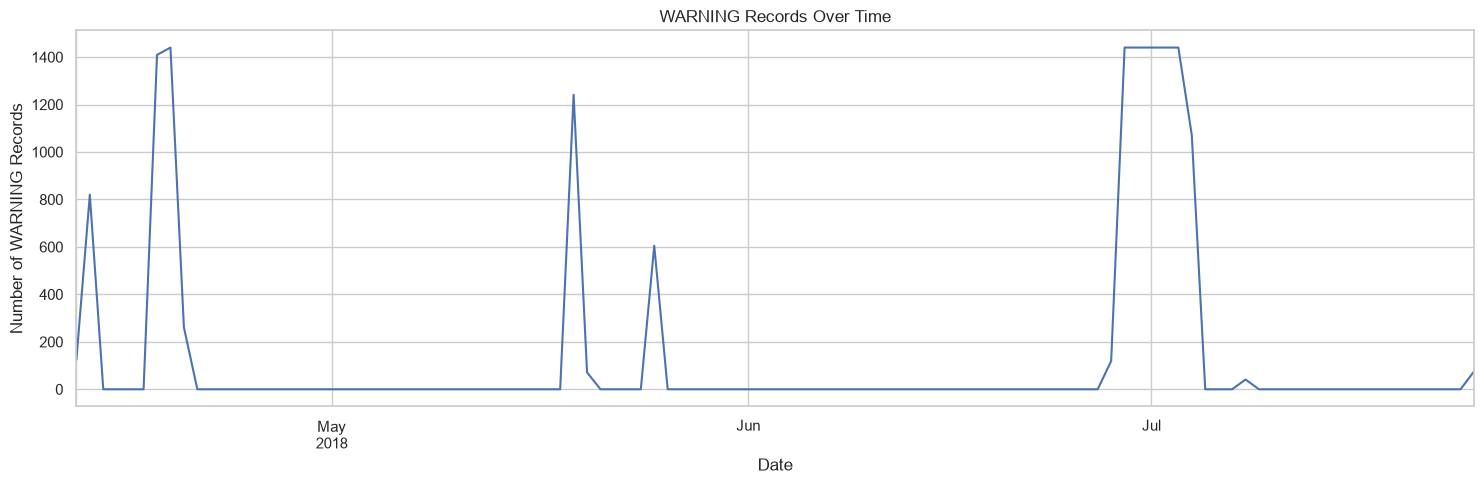

In [11]:
warning_over_time = (
    df.set_index("timestamp")
    .resample("D")
    .size()
)

plt.figure(figsize=(15, 5))

warning_over_time.plot()

plt.title("WARNING Records Over Time")

plt.xlabel("Date")

plt.ylabel("Number of WARNING Records")

plt.tight_layout()

plt.show()

Analysis results saved successfully!



# WARNING Analysis Conclusion

## Summary

- The dataset contains 14,477 WARNING records.
- 51 sensor columns were analyzed.
- Missing sensor values were handled during preprocessing.
- Sensor statistics and correlations were calculated.
- Daily WARNING records were visualized.

## Conclusion

The analysis helps us understand machine sensor
behavior during the WARNING condition.

Further investigation is needed to identify which
sensor patterns can indicate an upcoming machine
warning.


In [13]:
# Select sensor columns
sensor_columns = [
    col for col in df.columns
    if col.startswith("sensor_")
]

# Calculate sensor variability
sensor_variability = df[sensor_columns].std()

# Sort sensors by standard deviation
top_sensors = sensor_variability.sort_values(
    ascending=False
).head(10)

print("Top 10 sensors with highest variability:")

display(top_sensors)

Top 10 sensors with highest variability:


sensor_51    342.718625
sensor_36    221.124167
sensor_32    203.315186
sensor_31    186.957632
sensor_29    138.645740
sensor_27    120.129857
sensor_04    118.361795
sensor_28    112.294855
sensor_23     97.875129
sensor_35     96.547072
dtype: float64

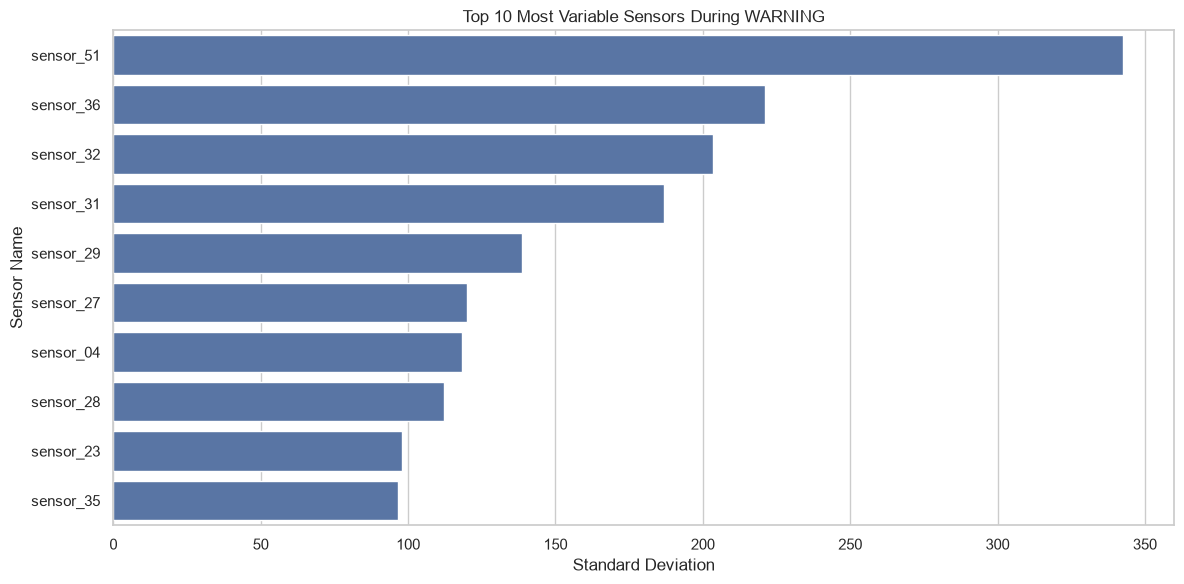

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_sensors.values,
    y=top_sensors.index
)

plt.title("Top 10 Most Variable Sensors During WARNING")

plt.xlabel("Standard Deviation")

plt.ylabel("Sensor Name")

plt.tight_layout()

plt.show()

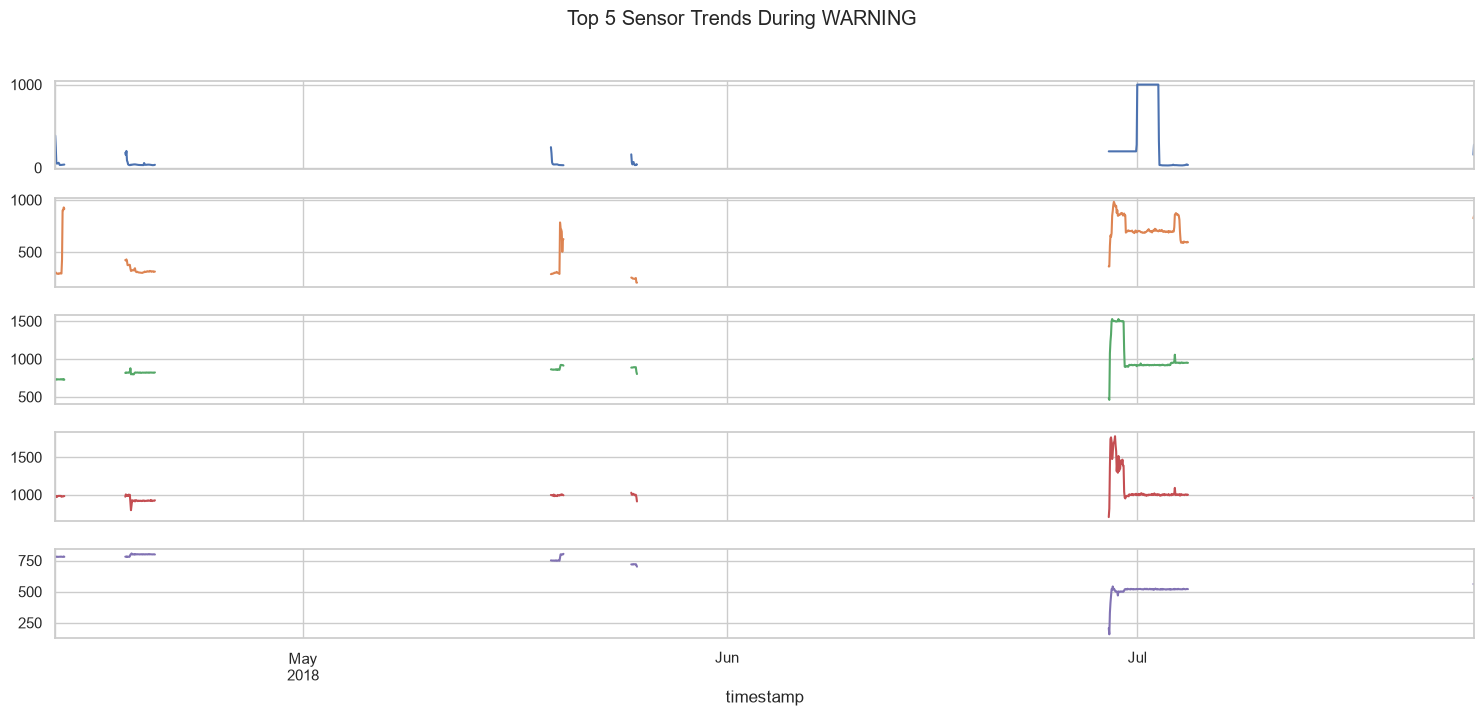

In [15]:
# Select top 5 sensors
selected_sensors = top_sensors.head(5).index.tolist()

# Resample data hourly
hourly_data = (
    df.set_index("timestamp")[selected_sensors]
    .resample("1h")
    .mean()
)

# Plot sensor trends
hourly_data.plot(
    figsize=(15, 7),
    subplots=True,
    layout=(5, 1),
    sharex=True,
    legend=False
)

plt.suptitle(
    "Top 5 Sensor Trends During WARNING",
    y=1.02
)

plt.tight_layout()

plt.show()

In [16]:
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save top sensor statistics
top_sensors.to_csv(
    OUTPUT_DIR / "top_warning_sensors.csv"
)

# Save hourly sensor trends
hourly_data.to_csv(
    OUTPUT_DIR / "warning_sensor_trends.csv"
)

print("Advanced WARNING analysis saved successfully!")

Advanced WARNING analysis saved successfully!


In [18]:

# Load the original sensor dataset
FULL_DATA_PATH = BASE_DIR / "data" / "sensor.csv"

df_all = pd.read_csv(FULL_DATA_PATH)

print("Full dataset loaded:", df_all.shape)

# Convert sensor columns to numeric
sensor_columns = [
    col for col in df_all.columns
    if col.startswith("sensor_")
]

for col in sensor_columns:
    df_all[col] = pd.to_numeric(
        df_all[col],
        errors="coerce"
    )

# Remove empty sensor columns
empty_columns = [
    col for col in sensor_columns
    if df_all[col].isna().all()
]

df_all = df_all.drop(columns=empty_columns)

sensor_columns = [
    col for col in df_all.columns
    if col.startswith("sensor_")
]

# Fill missing sensor values
for col in sensor_columns:
    median_value = df_all[col].median()
    if pd.notna(median_value):
        df_all[col] = df_all[col].fillna(median_value)

# Create target labels
status_mapping = {
    "NORMAL": "NORMAL",
    "RECOVERING": "WARNING",
    "BROKEN": "FAULT"
}

df_all["target"] = df_all["machine_status"].map(
    status_mapping
)

print("\nMachine status distribution:")
print(df_all["target"].value_counts())

# Select WARNING and NORMAL only
comparison_df = df_all[
    df_all["target"].isin(["WARNING", "NORMAL"])
].copy()

print("\nComparison dataset:", comparison_df.shape)
print("Cell 17 completed successfully!")


Full dataset loaded: (220320, 55)

Machine status distribution:
target
NORMAL     205836
WARNING     14477
FAULT           7
Name: count, dtype: int64

Comparison dataset: (220313, 55)
Cell 17 completed successfully!


In [19]:
sensor_columns = [
    col for col in comparison_df.columns
    if col.startswith("sensor_")
]

warning_data = comparison_df[
    comparison_df["target"] == "WARNING"
]

normal_data = comparison_df[
    comparison_df["target"] == "NORMAL"
]

comparison_results = pd.DataFrame({
    "WARNING_Mean": warning_data[sensor_columns].mean(),
    "NORMAL_Mean": normal_data[sensor_columns].mean(),
    "WARNING_Std": warning_data[sensor_columns].std(),
    "NORMAL_Std": normal_data[sensor_columns].std()
})

comparison_results["Mean_Difference"] = (
    comparison_results["WARNING_Mean"]
    - comparison_results["NORMAL_Mean"]
)

comparison_results["Absolute_Difference"] = (
    comparison_results["Mean_Difference"].abs()
)

display(
    comparison_results.sort_values(
        "Absolute_Difference",
        ascending=False
    ).head(15)
)

,WARNING_Mean,NORMAL_Mean,WARNING_Std,NORMAL_Std,Mean_Difference,Absolute_Difference
sensor_04,93.220460,625.673758,118.361795,50.820988,-532.453298,532.453298
sensor_28,1091.685628,834.815744,112.294855,315.720992,256.869884,256.869884
sensor_31,1032.790560,851.405723,186.957632,285.355701,181.384837,181.384837
sensor_50,40.880925,197.094606,36.324253,36.009346,-156.213681,156.213681
sensor_32,938.295231,794.882835,203.315186,261.557230,143.412396,143.412396
sensor_48,37.186141,158.884038,31.859654,78.703688,-121.697896,121.697896
sensor_23,1027.865195,915.212383,97.875129,299.404761,112.652812,112.652812
sensor_30,698.981515,608.729868,68.014728,200.246457,90.251647,90.251647
sensor_21,868.417272,791.155750,59.049431,233.143981,77.261522,77.261522
sensor_26,857.121272,781.446884,95.571247,253.175704,75.674388,75.674388


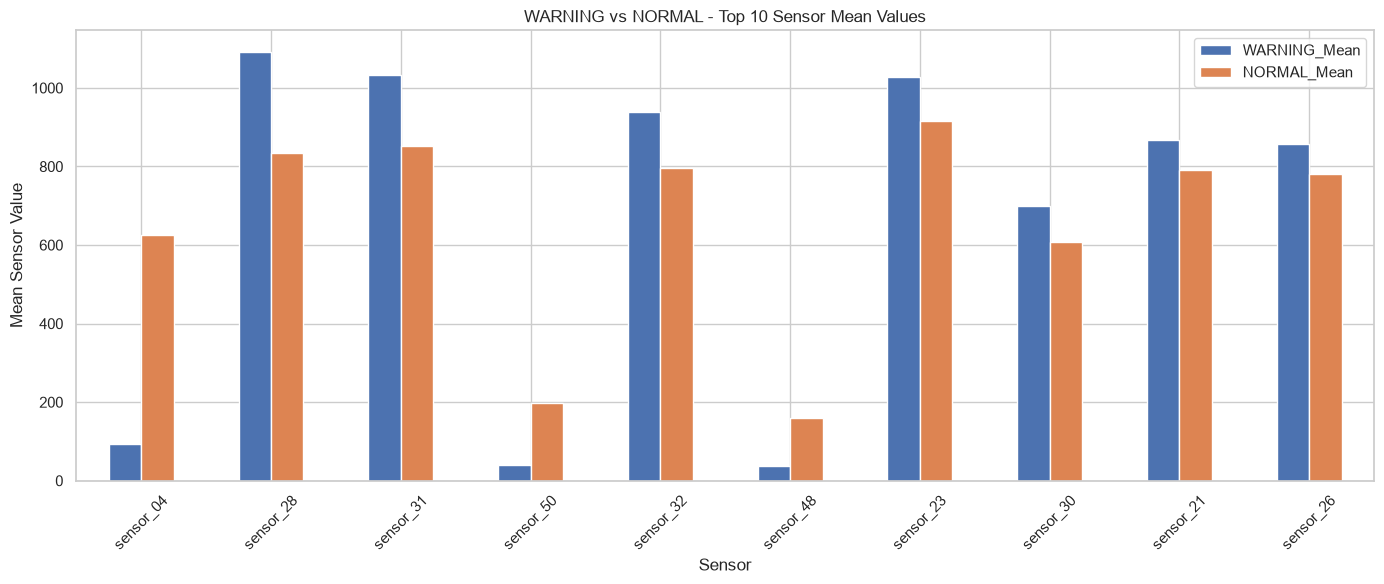

In [20]:
top_different_sensors = (
    comparison_results
    .sort_values(
        "Absolute_Difference",
        ascending=False
    )
    .head(10)
)

plot_data = top_different_sensors[
    ["WARNING_Mean", "NORMAL_Mean"]
]

plot_data.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("WARNING vs NORMAL - Top 10 Sensor Mean Values")

plt.xlabel("Sensor")

plt.ylabel("Mean Sensor Value")

plt.xticks(rotation=45)

plt.legend()

plt.tight_layout()

plt.show()

In [21]:
comparison_results.to_csv(
    OUTPUT_DIR / "warning_normal_comparison.csv"
)

top_different_sensors.to_csv(
    OUTPUT_DIR / "top_warning_normal_sensors.csv"
)

print("WARNING vs NORMAL comparison saved successfully!")

WARNING vs NORMAL comparison saved successfully!
